In [1]:
from requirements import *

# Extended Data Figure 1

In [2]:
adata_xenv1 = sc.read_h5ad(XEN_V1)

## ED Figure 1c. 10x Multimodal vs Baysor per Leiden cluster

In [3]:
dir_di = {'10x Multimodal': ['region2_0015829', 'region3_0078981', 'region1_0069331', 'region1_0069146', 
                             'region1_0033583', 'region1_0069737', 'region2_0069737', 'region2_0015858', 
                             'region2_0069146', 'region1_0015858', 'region2_0079269', 'region1_0065604', 
                             'region2_0069320', 'region1_0078989', 'region2_0069330', 'region3_0078989', 
                             'region2_0065604', 'region2_0069331', 'region1_0079269', 'region4_0065604', 
                             'region2_0079272', 'region3_0042591', 'region1_0069187', 'region2_0069145', 
                             'region2_0065607', 'region2_0078981', 'region1_0079272', 'region2_0069594', 
                             'region1_0069808', 'region2_0069670', 'region3_0065604', 'region1_0069670', 
                             'region1_0078981', 'region1_0015829', 'region1_0065607', 'region2_0069641', 
                             'region1_0064838', 'region1_0042591', 'region2_0064838', 'region2_0069480', 
                             'region1_0042592', 'region2_0069665', 'region3_0065607', 'region1_0069330', 
                             'region2_0078989', 'region2_0033583', 'region2_0069478', 'region1_0069595', 
                             'region1_0069480', 'region1_0069478', 'region1_0069320', 'region2_0069595', 
                             'region2_0042591', 'region2_0069319', 'region1_0069665', 'region1_0069319', 
                             'region1_0069594', 'region1_0069641', 'region1_0069145'], 
          'Baysor': ['region3_0015400', 'region1_0042580', 'region2_0027861', 'region1_0036579', 
                     'region2_0015400', 'region1_0027609', 'region1_0015399', 'region1_0043114', 
                     'region1_0027861', 'region1_0027612', 'region1_0027860', 'region1_0015400', 
                     'region1_0036509', 'region1_0011552', 'region1_0011482', 'region1_0011549', 
                     'region3_0011552', 'region1_0042581', 'region2_0011552', 'region1_0011479', 'region1_0043106']}


<Figure size 1200x280 with 0 Axes>

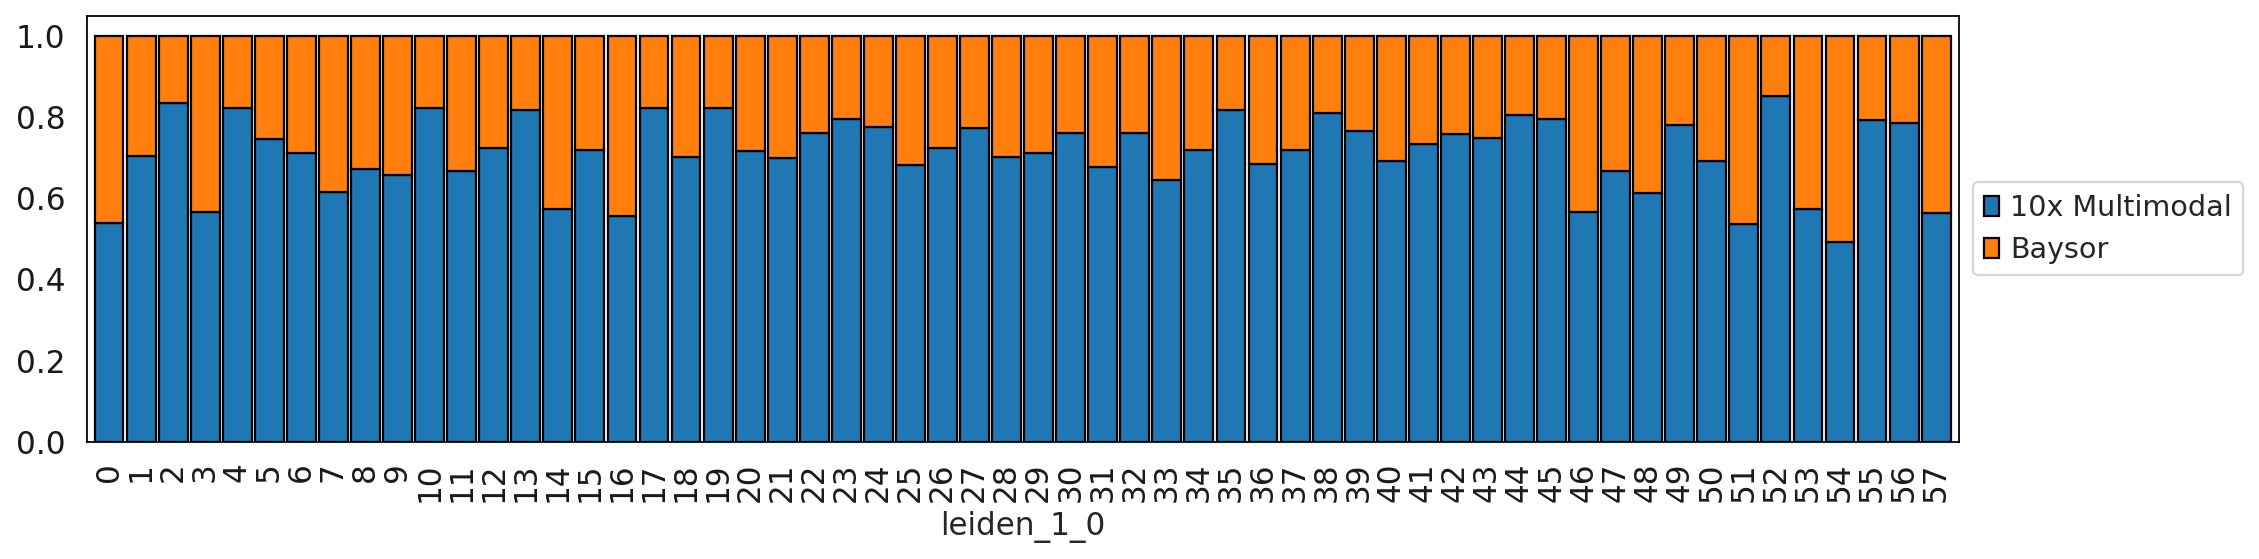

In [5]:
adata_xenv1.obs['Segmentation'] = '10x Multimodal'
adata_xenv1.obs['Segmentation'][adata_xenv1.obs['sample_name'].isin(dir_di['Baysor'])] = 'Baysor'

leiden_size = adata_xenv1.obs['leiden_1_0'].value_counts()
tmp = adata_xenv1[adata_xenv1.obs['leiden_1_0'].isin(leiden_size[leiden_size >= 100].index)]

df_tmp = pd.crosstab(index=tmp.obs['leiden_1_0'], columns=tmp.obs['Segmentation'])#.apply(lambda x: x/x.sum(), axis=1)
sc.set_figure_params(figsize=(15, 3.5))
f = plt.figure()
df_tmp.apply(lambda x: x/x.sum(), axis=1).plot(kind='bar', stacked=True, width = 0.9, edgecolor = 'black')
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)



## ED Figure 1d. Marker gene heatmap by cell type (Xenium)

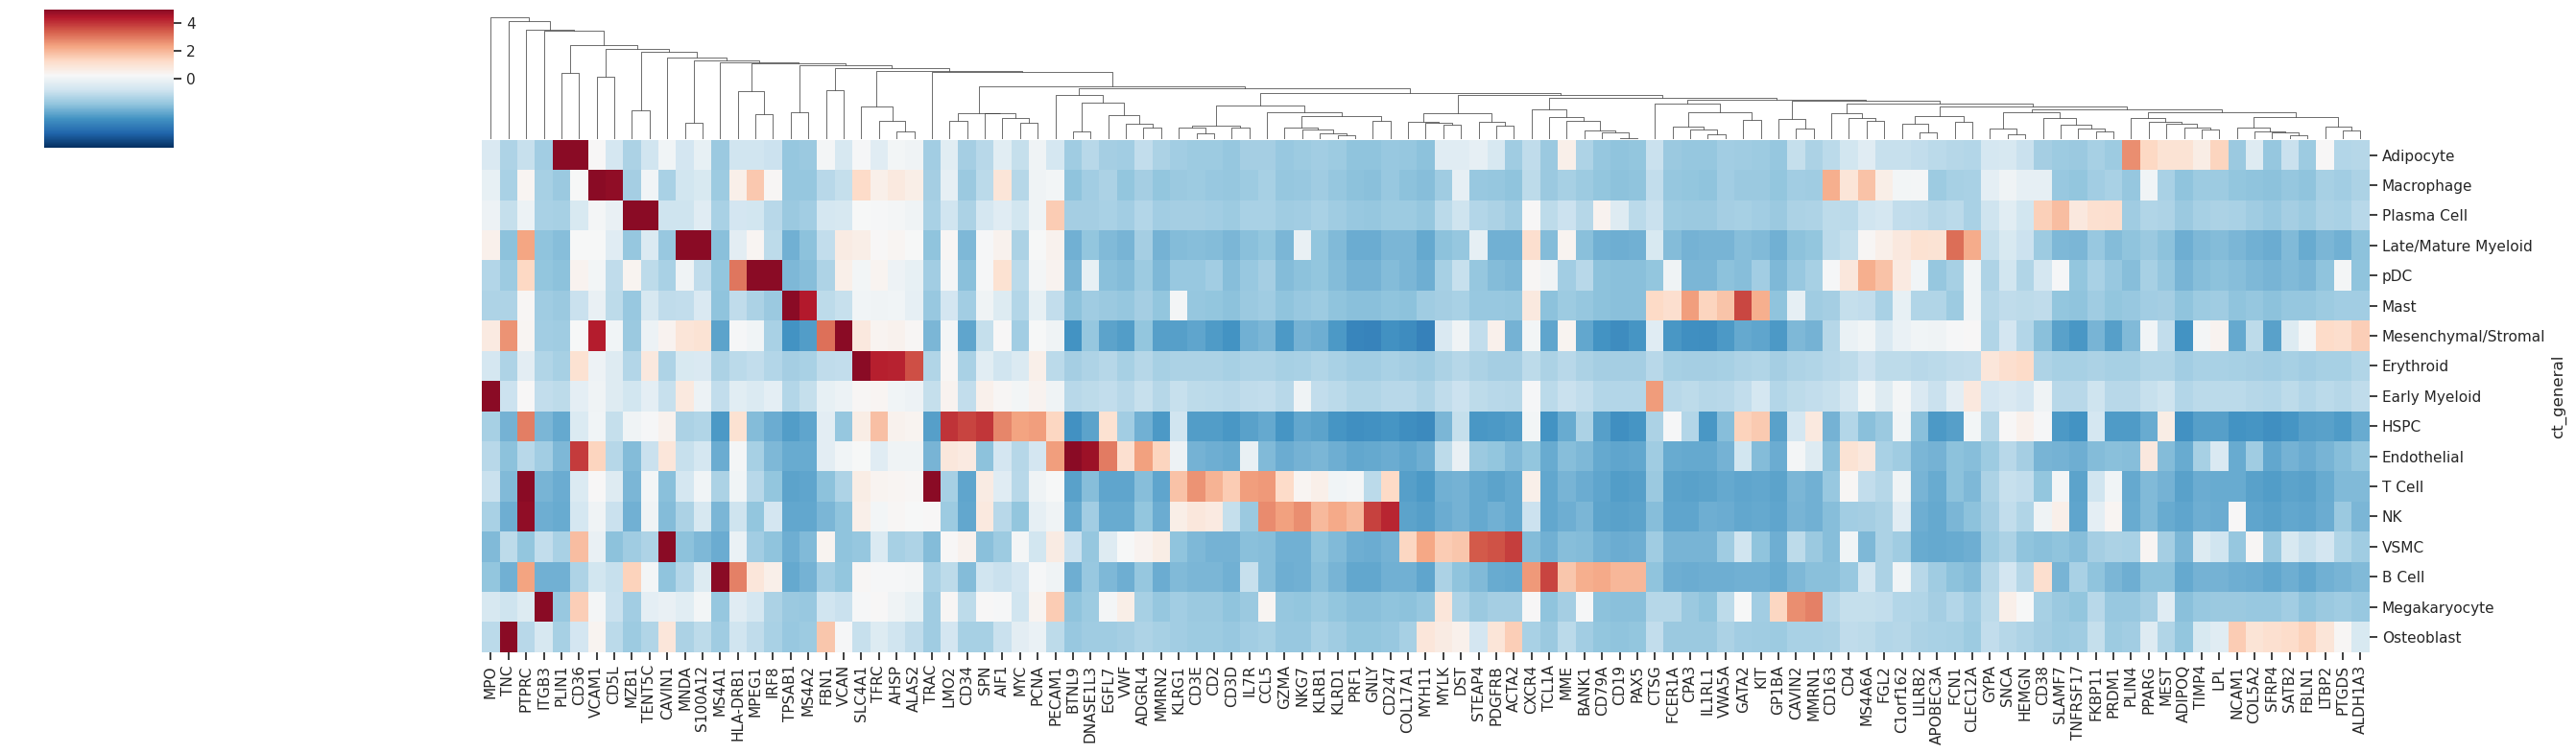

In [4]:
# top 10 expressed genes in each cell type
from scipy import stats
import matplotlib.colors as colors

topgenes = dict()
alltopgenes = set()
for ct in adata_xenv1.obs['ct_general'].unique():
    tmp = adata_xenv1[adata_xenv1.obs['ct_general'] == ct]
    tmp.X_norm = sc.pp.normalize_total(tmp, target_sum=1, inplace=False)['X']
    tmp.var['mean_expression'] = np.ravel(tmp.X_norm.mean(0))
    df = pd.DataFrame(tmp.var.nlargest(10, 'mean_expression')['mean_expression'])
    topgenes[ct] = [x for x in df.index]
    alltopgenes.update([x for x in df.index])

genelst = [x for x in alltopgenes if not x in ['HLA-B','HLA-C','HLA-A','CXCL12','S100A9']]
df_topgenes = adata_xenv1[:,genelst]
df1 = pd.DataFrame.sparse.from_spmatrix(df_topgenes.X)
df1['ct_general'] = [x for x in df_topgenes.obs['ct_general']]
df1 = df1.groupby(['ct_general']).mean()
df1.columns = genelst
df1 = stats.zscore(df1, axis=1, nan_policy='omit')

vmin = -1
vmax = 5
norm = colors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
cmap = cmr.get_sub_cmap('RdBu_r', 0, 0.95)
#sns.set(font_scale=1.5)
df1 = df1.reindex(index = ['Adipocyte', 'Macrophage','Plasma Cell','Late/Mature Myeloid','pDC','Mast','Mesenchymal/Stromal','Erythroid','Early Myeloid','HSPC','Endothelial','T Cell','NK','VSMC','B Cell','Megakaryocyte','Osteoblast'])
sns.set_style("whitegrid", {'axes.grid' : False})
g = sns.clustermap(df1, yticklabels=True,  xticklabels=True, figsize=(27, 8), dendrogram_ratio = 0.2, col_cluster=True, row_cluster=False, cmap = cmap,norm = norm) #  linewidths=0.05, linecolor='black' z_score=1
ax = g.ax_heatmap
g.ax_heatmap.tick_params(right=True, bottom=True)

ax.grid(False)


## ED Figure 1e. Marker gene heatmap by lymphocyte subtype

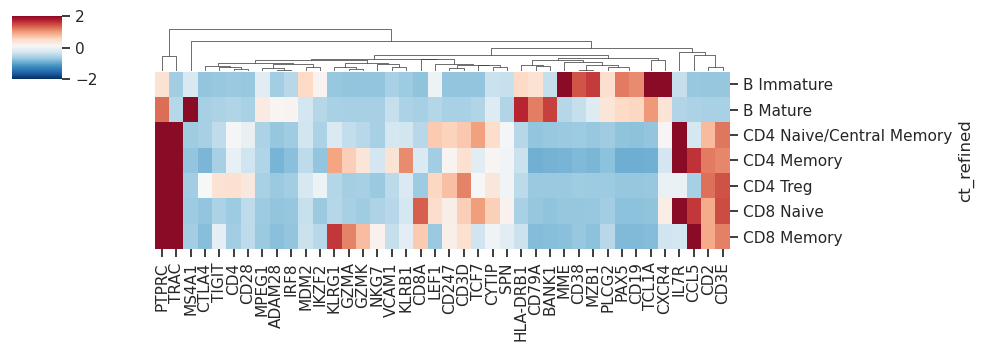

In [5]:
# top 15 expressed gene in each cell type
from scipy import stats
topgenes = dict()
alltopgenes = set()
for ct in ['CD8 Naive','CD8 Memory','CD4 Naive/Central Memory','CD4 Memory','CD4 Treg','B Immature','B Mature']:
    #print(ct)
    tmp = adata_xenv1[adata_xenv1.obs['ct_refined'] == ct]
    tmp.X_norm = sc.pp.normalize_total(tmp, target_sum=1, inplace=False)['X']
    tmp.var['mean_expression'] = np.ravel(tmp.X_norm.mean(0))
    df = pd.DataFrame(tmp.var.nlargest(15, 'mean_expression')['mean_expression'])
    topgenes[ct] = [x for x in df.index]
    alltopgenes.update([x for x in df.index])

genelst = [x for x in alltopgenes if not x in ['HLA-B','HLA-C','HLA-A','CXCL12','S100A9']]
df_topgenes = adata_xenv1[:,genelst]
df1 = pd.DataFrame.sparse.from_spmatrix(df_topgenes.X)
df1['ct_refined'] = [x for x in df_topgenes.obs['ct_refined']]
df1 = df1.groupby(['ct_refined']).mean()
df1.columns = genelst
df1 = stats.zscore(df1, axis=1, nan_policy='omit')

vmin = -2
vmax = 2
norm = colors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
cmap = cmr.get_sub_cmap('RdBu_r', 0, 0.95)
#sns.set(font_scale=1.5)
df1 = df1.reindex(index = ['B Immature','B Mature', 'CD4 Naive/Central Memory','CD4 Memory','CD4 Treg','CD8 Naive','CD8 Memory'])
sns.set_style("whitegrid", {'axes.grid' : False})
g = sns.clustermap(df1, yticklabels=True,  xticklabels=True, figsize=(10, 3.5), dendrogram_ratio = 0.2, row_cluster=False, cmap = cmap,norm = norm) #  linewidths=0.05, linecolor='black' z_score=1
ax = g.ax_heatmap
g.ax_heatmap.tick_params(right=True, bottom=True)

ax.grid(False)
